# Genetik Algoritma + Yapay Sinir Ağı — Uygulama
## 64 pikselin tamamına ihtiyaç var mı?

**Problem:** `load_digits` veri setindeki el yazısı rakamları 8×8 piksellik görüntülerden oluşur. Bir yapay sinir ağı, bu **64 pikselin tamamını** kullanarak rakamı tanıyabilir. Peki daha az pikselle benzer doğruluğa ulaşabilir miyiz?

Önce 64 pikseli kullanan bir YSA eğitin. Ardından **genetik algoritmayla hangi piksellerin kullanılacağını seçin**. Amacınız, **kullanılan piksel sayısını azaltırken rakam tanıma başarısını mümkün olduğunca korumak**.

GA'nın bireyi 64 elemanlı bir `0/1` dizisidir: **1 = piksel kullanılır**, **0 = o konumdaki piksel değeri sıfırlanır**. Giriş boyutu değişmez; GA, önceden eğittiğiniz YSA'nın **ağırlıklarını değiştirmez**.

**Hedef:** 64 pikselin tamamıyla alınan sonuç ile GA'nın seçtiği piksellerle alınan sonucu karşılaştırın.

Başlangıç hücresini çalıştırın. Çözümün yöntemini ve kod yapısını siz belirleyin. **Test verisini yalnızca son karşılaştırmada kullanın.**

---

Bu not defteri Google Colab düzenindedir. Colab'da ek kurulum gerekmez (`numpy`, `pandas`, `matplotlib`, `keras` ve `scikit-learn` hazır gelir). **Runtime → Run all** aynı sırayı çalıştırır. `SEED = 42` bu sırada aynı sayıları üretir. Çıktılar ve grafikler dosyaya kaydedilmiştir.


In [1]:
# HAZIR BAŞLANGIÇ HÜCRESİ — DEĞİŞTİRMEYİNİZ
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

# Sklearn'in hazır veri seti, indirme / dosya yükleme gerekmez.
digits = load_digits()
X = digits.data.astype('float32') / 16.0  # 1797 adet 8x8 görüntü → 64 sütun
y = digits.target.astype('int64')

# Önce test ayırılır; test yalnızca final aşamada kullanılır.
X_gelistirme, X_test, y_gelistirme, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_gelistirme, y_gelistirme, test_size=0.20,
    stratify=y_gelistirme, random_state=SEED
)

print('Eğitim:', X_train.shape, 'Doğrulama:', X_val.shape, 'Test:', X_test.shape)
print('Sınıflar:', np.unique(y_train))


Eğitim: (1149, 64) Doğrulama: (288, 64) Test: (360, 64)
Sınıflar: [0 1 2 3 4 5 6 7 8 9]


## Görev 1 — Veriyi tanıma

Veri setinin yapısını inceleyin. Her rakam sınıfından birer örnek görüntü gösterin ve giriş/çıkış değişkenlerini açıklayın.


Veri seti: sklearn.load_digits — 8×8 el yazısı rakamlar
Tüm örnek sayısı : 1797
Giriş X şekli    : (1797, 64)   (satır = görüntü, sütun = piksel)
Çıkış y şekli    : (1797,)   (her görüntünün rakamı)
Piksel aralığı   : 0 ile 1 arası
Ham piksel 0–16 idi; başlangıç hücresi 16'ya bölerek 0–1 yaptı.
Sınıflar         : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Sınıf dağılımı (tüm veri):
       adet
rakam      
0       178
1       182
2       177
3       183
4       181
5       182
6       181
7       179
8       174
9       180

Eğitim: 1149 örnek | Doğrulama: 288 örnek | Test: 360 örnek
Test kümesine bu görevde bakılmıyor. Model ve GA yalnız eğitim ile doğrulama kullanacak.

Eğitimden bir 8×8 matris (etiket 5). Görüntü satır satır düzleştirilmiştir.
[[0.   0.38 0.81 0.31 0.5  0.5  0.06 0.  ]
 [0.   0.5  1.   1.   1.   1.   0.38 0.  ]
 [0.   0.38 1.   0.56 0.38 0.25 0.   0.  ]
 [0.   0.38 1.   1.   0.94 0.31 0.   0.  ]
 [0.   0.   0.25 0.31 0.94 0.75 0.   0.  ]
 [0.   0.   0.   0.19 1.   0.56 0.   0. 

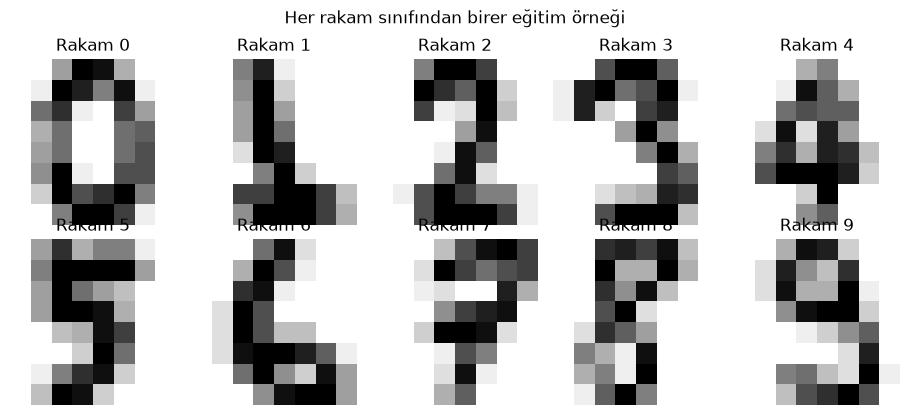

In [2]:
%matplotlib inline

print('Veri seti: sklearn.load_digits — 8×8 el yazısı rakamlar')
print(f'Tüm örnek sayısı : {len(X)}')
print(f'Giriş X şekli    : {X.shape}   (satır = görüntü, sütun = piksel)')
print(f'Çıkış y şekli    : {y.shape}   (her görüntünün rakamı)')
print(f'Piksel aralığı   : {float(X.min()):.0f} ile {float(X.max()):.0f} arası')
print('Ham piksel 0–16 idi; başlangıç hücresi 16\'ya bölerek 0–1 yaptı.')
print(f'Sınıflar         : {[int(s) for s in np.unique(y)]}')
print()
print('Sınıf dağılımı (tüm veri):')
dagilim = pd.Series(y).value_counts().sort_index().rename_axis('rakam').to_frame('adet')
print(dagilim.to_string())
print()
print(f'Eğitim: {len(X_train)} örnek | Doğrulama: {len(X_val)} örnek | Test: {len(X_test)} örnek')
print('Test kümesine bu görevde bakılmıyor. Model ve GA yalnız eğitim ile doğrulama kullanacak.')
print()

ornek_no = int(np.where(y_train == 5)[0][0])
print(f'Eğitimden bir 8×8 matris (etiket {y_train[ornek_no]}). Görüntü satır satır düzleştirilmiştir.')
print(np.round(X_train[ornek_no].reshape(8, 8), 2))
print()
print('Giriş değişkeni X: modelin okuduğu 64 piksel.')
print('Çıkış değişkeni y: görüntüdeki rakam. 0–9 arası 10 sınıf, tam sayı etiket.')

fig, axes = plt.subplots(2, 5, figsize=(9.2, 4.2))
for rakam, ax in enumerate(axes.ravel()):
    idx = int(np.where(y_train == rakam)[0][0])
    ax.imshow(X_train[idx].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(f'Rakam {rakam}')
    ax.axis('off')
fig.suptitle('Her rakam sınıfından birer eğitim örneği')
fig.tight_layout()
plt.show()


## Görev 2 — YSA modeli

64 pikselin tamamını kullanan, 0–9 rakamlarını sınıflandıran bir YSA oluşturup eğitin. Mimarisini ve eğitim ayarlarını siz seçin.

**Çıktı:** Model özeti, eğitim/doğrulama grafiği ve doğrulama başarısı. Model tercihinizi kısaca gerekçelendirin. Bu modeli GA boyunca yeniden eğitmeyin.


Model: "rakam_ysa"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gizli_128 (Dense)               │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gizli_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rakam_10 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 17,226 (67.29 KB)

Trainable params: 17,226 (67.29 KB)

Non-trainable params: 0 (0.00 B)


Çalışan epoch sayısı: 13
Epoch 01 | loss=1.9606 acc=0.4822 | val_loss=1.4533 val_acc=0.8958
Epoch 05 | loss=0.2255 acc=0.9582 | val_loss=0.1896 val_acc=0.9653
Epoch 10 | loss=0.0974 acc=0.9817 | val_loss=0.1160 val_acc=0.9653
Epoch 13 | loss=0.0683 acc=0.9896 | val_loss=0.1075 val_acc=0.9653

En yüksek doğrulama başarısının geldiği epoch: 5
Doğrulama kaybı    : 0.1896
Doğrulama başarısı : 0.9653  (96.53%)
Bu ağırlıklar GA boyunca sabit kalır. Bundan sonra model.fit çağrılmaz.
Test kümesi bu adımda kullanılmadı.


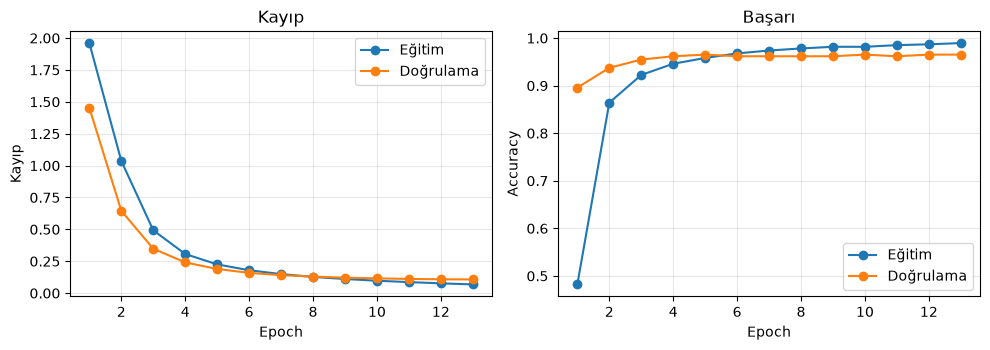

In [3]:
# Tam bağlı ağ: 64 giriş → 128 ReLU → 64 ReLU → 10 softmax.
# Giriş zaten düz 64 sayı olduğu için evrişim katmanı kullanmadım.
# Dropout yok: deney, "hangi pikseller açık" sorusuna bakıyor;
# eğitimde rastgele nöron kapatmak bu ölçümü karıştırır.
# Erken durdurma, doğrulama başarısı 8 epoch boyunca artmazsa
# en iyi ağırlıkları geri yükler. Kayıp, 10 sınıflı tam sayı etiket
# için sparse categorical crossentropy. Optimizasyon Adam, öğrenme hızı 0.001.

model = keras.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(128, activation='relu', name='gizli_128'),
    layers.Dense(64, activation='relu', name='gizli_64'),
    layers.Dense(10, activation='softmax', name='rakam_10'),
], name='rakam_ysa')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

model.summary()

gecmis = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    verbose=0,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            patience=8,
            restore_best_weights=True,
        )
    ],
)

hist = gecmis.history
print()
print(f'Çalışan epoch sayısı: {len(hist["loss"])}')
for epoch in range(len(hist['loss'])):
    son = epoch == len(hist['loss']) - 1
    if epoch == 0 or (epoch + 1) % 5 == 0 or son:
        print(
            f"Epoch {epoch + 1:02d} | "
            f"loss={hist['loss'][epoch]:.4f} acc={hist['accuracy'][epoch]:.4f} | "
            f"val_loss={hist['val_loss'][epoch]:.4f} val_acc={hist['val_accuracy'][epoch]:.4f}"
        )

val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
en_iyi_epoch = int(np.argmax(hist['val_accuracy'])) + 1
print()
print(f'En yüksek doğrulama başarısının geldiği epoch: {en_iyi_epoch}')
print(f'Doğrulama kaybı    : {val_loss:.4f}')
print(f'Doğrulama başarısı : {val_acc:.4f}  ({val_acc * 100:.2f}%)')
print('Bu ağırlıklar GA boyunca sabit kalır. Bundan sonra model.fit çağrılmaz.')
print('Test kümesi bu adımda kullanılmadı.')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
epoch_ekseni = range(1, len(hist['loss']) + 1)
axes[0].plot(epoch_ekseni, hist['loss'], marker='o', label='Eğitim')
axes[0].plot(epoch_ekseni, hist['val_loss'], marker='o', label='Doğrulama')
axes[0].set_title('Kayıp')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Kayıp')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(epoch_ekseni, hist['accuracy'], marker='o', label='Eğitim')
axes[1].plot(epoch_ekseni, hist['val_accuracy'], marker='o', label='Doğrulama')
axes[1].set_title('Başarı')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## Görev 3 — Kromozom ve popülasyon

Piksel seçimini temsil eden **64 bitlik kromozomlar** ve en az **8 bireyden oluşan** bir başlangıç popülasyonu oluşturun. Her bireyde **12–48 piksel** seçili olsun.

**Çıktı:** Başlangıç popülasyonu ve seçilen piksel sayıları.


In [4]:
N_PIKSEL = 64
MIN_PIKSEL = 12
MAX_PIKSEL = 48
POP_BOYUTU = 24  # en az 8 istendi; arama için 24 birey kullandım

def piksel_sayisi(kromozom):
    return int(np.sum(kromozom))

def bit_yazi(kromozom):
    return ''.join(str(int(bit)) for bit in np.asarray(kromozom).ravel())

def rastgele_kromozom():
    """12 ile 48 arasında rastgele sayıda 1 içeren 64 bit."""
    adet = random.randint(MIN_PIKSEL, MAX_PIKSEL)
    kromozom = np.zeros(N_PIKSEL, dtype=np.int8)
    secilen = np.random.choice(N_PIKSEL, size=adet, replace=False)
    kromozom[secilen] = 1
    return kromozom

def kromozom_gecerli(kromozom):
    kromozom = np.asarray(kromozom)
    if kromozom.shape != (N_PIKSEL,):
        return False
    if not np.isin(kromozom, [0, 1]).all():
        return False
    return MIN_PIKSEL <= piksel_sayisi(kromozom) <= MAX_PIKSEL

populasyon = [rastgele_kromozom() for _ in range(POP_BOYUTU)]

print(f'Popülasyon boyutu : {len(populasyon)} birey')
print(f'Kromozom uzunluğu : {N_PIKSEL} bit   (1 = piksel kullanılır, 0 = sıfırlanır)')
print(f'İzin verilen piksel sayısı: {MIN_PIKSEL}–{MAX_PIKSEL}')
print()
baslangic_tablosu = pd.DataFrame({
    'birey': np.arange(POP_BOYUTU),
    'piksel_sayisi': [piksel_sayisi(k) for k in populasyon],
    'kromozom': [bit_yazi(k) for k in populasyon],
})
print(baslangic_tablosu.to_string(index=False))
print()
print(
    f"Piksel sayısı → min {baslangic_tablosu['piksel_sayisi'].min()}, "
    f"ortalama {baslangic_tablosu['piksel_sayisi'].mean():.1f}, "
    f"max {baslangic_tablosu['piksel_sayisi'].max()}"
)
print(
    'Hepsi 12–48 aralığında:',
    bool(baslangic_tablosu['piksel_sayisi'].between(MIN_PIKSEL, MAX_PIKSEL).all()),
)


Popülasyon boyutu : 24 birey
Kromozom uzunluğu : 64 bit   (1 = piksel kullanılır, 0 = sıfırlanır)
İzin verilen piksel sayısı: 12–48

 birey  piksel_sayisi                                                         kromozom
     0             29 1001111011001100110100000100000101101000110010010110101110100100
     1             27 1010101000110000001101000010010010001110100011000011101101001011
     2             26 0100010101010001111110001001101011000100110000010101000101001000
     3             20 0000101001000101010101001000101001010000000011001000000111000010
     4             18 0000000001001110000010000010000001011100001100011000110011000000
     5             46 1101110011101111011000111111101101111011111110101100110011111101
     6             17 0011000000000000010010000000000000000000100011100010101111111000
     7             39 0111111101101110010111010010101010110100101111000111110011000111
     8             14 00000100000000100000110001000000010000100000001101110100001000

## Görev 4 — Uygunluk (fitness)

Bireyleri karşılaştırmak için **doğrulama başarısını ödüllendiren, fazla piksel kullanımını cezalandıran** bir fitness yaklaşımı oluşturun. Geçersiz kromozomları (12–48 aralığının dışında kalanları) dikkate alın. YSA ağırlıklarını değiştirmeyin.

**Çıktı:** En az iki bireyin piksel sayısı, doğrulama başarısı ve fitness değeri. Seçtiğiniz fitness yaklaşımını kısaca açıklayın.


In [5]:
# fitness = doğrulama başarısı - 0.20 * (piksel sayısı / 64)
# Katsayı 0.20: piksel oranı 1 olsaydı başarıdan 0.20 puan düşerdi.
# 12 pikselde ceza ≈ 0.037, 48 pikselde ceza ≈ 0.150.
# Aynı başarıya daha az pikselle gelen birey daha yüksek fitness alır.
# 12–48 dışındaki kromozom geçersizdir; fitness = -1 (geçerli skorların altında).
# Ölçüm, sabit ağın doğrulama kümesi üzerindeki ileri yayılımıdır.

PIKSEL_CEZA = 0.20
_uygunluk_onbellek = {}

def maskele(veri, kromozom):
    """Kapalı pikselleri 0 yapar. Giriş genişliği 64 olarak kalır."""
    return veri * np.asarray(kromozom, dtype=np.float32)

def basari_olc(kromozom, veri, etiket):
    olasilik = model(maskele(veri, kromozom), training=False).numpy()
    tahmin = np.argmax(olasilik, axis=1)
    return float(np.mean(tahmin == etiket))

def uygunluk(kromozom, veri=None, etiket=None):
    kromozom = np.asarray(kromozom, dtype=np.int8)
    dogrulama_mi = veri is None
    if dogrulama_mi:
        veri, etiket = X_val, y_val
    anahtar = kromozom.tobytes()
    if dogrulama_mi and anahtar in _uygunluk_onbellek:
        return _uygunluk_onbellek[anahtar]
    n = piksel_sayisi(kromozom)
    basari = basari_olc(kromozom, veri, etiket)
    if kromozom_gecerli(kromozom):
        fitness = basari - PIKSEL_CEZA * (n / N_PIKSEL)
    else:
        fitness = -1.0
    sonuc = (float(fitness), float(basari), int(n))
    if dogrulama_mi:
        _uygunluk_onbellek[anahtar] = sonuc
    return sonuc

print('Fitness = doğrulama_başarısı − 0.20 × (piksel_sayısı / 64)')
print('12–48 dışında fitness = −1. Ağırlıklar değişmez; kapalı piksel 0 girer.')
print()

alt = np.zeros(N_PIKSEL, dtype=np.int8)
alt[np.random.choice(N_PIKSEL, size=MIN_PIKSEL, replace=False)] = 1
ust = np.zeros(N_PIKSEL, dtype=np.int8)
ust[np.random.choice(N_PIKSEL, size=MAX_PIKSEL, replace=False)] = 1

satirlar = []
for ad, krom in [
    ('Popülasyon birey 0', populasyon[0]),
    ('Popülasyon birey 1', populasyon[1]),
    ('Alt sınır (12 piksel)', alt),
    ('Üst sınır (48 piksel)', ust),
    ('Geçersiz (64 piksel)', np.ones(N_PIKSEL, dtype=np.int8)),
    ('Geçersiz (0 piksel)', np.zeros(N_PIKSEL, dtype=np.int8)),
]:
    fitness, basari, n = uygunluk(krom)
    satirlar.append({
        'birey': ad,
        'piksel': n,
        'gecerli': 'evet' if kromozom_gecerli(krom) else 'hayır',
        'dogrulama_basarisi': round(basari, 4),
        'fitness': round(fitness, 4),
    })

print(pd.DataFrame(satirlar).to_string(index=False))
print()
print('64 pikselde doğruluk yüksek kalsa da aralık dışında olduğu için fitness −1 olur.')
print('0 pikselde ağ bütün girişleri 0 görür; başarı düşer, kromozom yine geçersizdir.')
print('Sayılar doğrulama kümesindendir. Test kümesi bu hücrede kullanılmadı.')


Fitness = doğrulama_başarısı − 0.20 × (piksel_sayısı / 64)
12–48 dışında fitness = −1. Ağırlıklar değişmez; kapalı piksel 0 girer.

                birey  piksel gecerli  dogrulama_basarisi  fitness
   Popülasyon birey 0      29    evet              0.6146   0.5240
   Popülasyon birey 1      27    evet              0.6493   0.5649
Alt sınır (12 piksel)      12    evet              0.2500   0.2125
Üst sınır (48 piksel)      48    evet              0.8889   0.7389
 Geçersiz (64 piksel)      64   hayır              0.9653  -1.0000
  Geçersiz (0 piksel)       0   hayır              0.1007  -1.0000

64 pikselde doğruluk yüksek kalsa da aralık dışında olduğu için fitness −1 olur.
0 pikselde ağ bütün girişleri 0 görür; başarı düşer, kromozom yine geçersizdir.
Sayılar doğrulama kümesindendir. Test kümesi bu hücrede kullanılmadı.


## Görev 5 — Genetik algoritma işlemleri

Daha önce öğrendiğiniz **seçim, çaprazlama, mutasyon ve elitizm** işlemlerini kullanarak yeni bireyler üretin. Kullanacağınız yöntemlere siz karar verin. Kromozom ve piksel sayısı kısıtlarını koruyun.

**Çıktı:** Ebeveyn, çocuk ve mutasyon örnekleri.


In [6]:
# Seçim: 3 bireylik turnuva. En yüksek fitness ebeveyn olur.
# Çaprazlama: tek nokta. Kesitten sonra bitler yer değiştirir.
#   Olasılık 0.90. Aksi halde ebeveynler kopyalanır.
# Mutasyon: her bit 0.03 olasılıkla tersine döner (64 bitte yaklaşık 2 bit).
# Onarım: çaprazlama veya mutasyon piksel sayısını 12–48 dışına iterse
#   fazlalık 1'ler kapatılır ya da eksik kadar 0, 1 yapılır.
# Elitizm: her nesilde en iyi 2 birey değişmeden yeni popülasyona yazılır.

ELIT_SAYISI = 2
TURNUVA_K = 3
CAPRAZ_OLASILIK = 0.90
MUTASYON_P = 0.03

def onar(kromozom):
    krom = np.asarray(kromozom, dtype=np.int8).copy()
    n = piksel_sayisi(krom)
    if n > MAX_PIKSEL:
        acik = np.where(krom == 1)[0]
        kapat = np.random.choice(acik, size=n - MAX_PIKSEL, replace=False)
        krom[kapat] = 0
    elif n < MIN_PIKSEL:
        kapali = np.where(krom == 0)[0]
        ac = np.random.choice(kapali, size=MIN_PIKSEL - n, replace=False)
        krom[ac] = 1
    return krom

def turnuva_sec(pop, skorlar, k=TURNUVA_K):
    adaylar = random.sample(range(len(pop)), k)
    kazanan = max(adaylar, key=lambda i: skorlar[i])
    return pop[kazanan].copy()

def caprazla(ebeveyn_a, ebeveyn_b):
    if random.random() > CAPRAZ_OLASILIK:
        return ebeveyn_a.copy(), ebeveyn_b.copy(), None
    nokta = random.randint(1, N_PIKSEL - 1)
    ham_1 = np.concatenate([ebeveyn_a[:nokta], ebeveyn_b[nokta:]]).astype(np.int8)
    ham_2 = np.concatenate([ebeveyn_b[:nokta], ebeveyn_a[nokta:]]).astype(np.int8)
    return onar(ham_1), onar(ham_2), nokta

def mutasyon(kromozom, p=MUTASYON_P):
    yeni = np.asarray(kromozom, dtype=np.int8).copy()
    degisen = []
    for i in range(N_PIKSEL):
        if random.random() < p:
            yeni[i] = 1 - int(yeni[i])
            degisen.append(i)
    return onar(yeni), degisen

def goster(ad, krom):
    print(f'{ad:22s} piksel={piksel_sayisi(krom):2d}  geçerli={kromozom_gecerli(krom)}')
    print(' ', bit_yazi(krom))

skorlar = [uygunluk(k)[0] for k in populasyon]
sira_on = sorted(range(len(populasyon)), key=lambda i: skorlar[i], reverse=True)

# Örnek kasıtlı seçildi: olasılık yüzünden kesim veya mutasyon boş kalmasın.
# Asıl döngüde kesim noktası 1–63 arasında rastgele çekilir, her bit 0.03 ile döner.
ebeveyn_a = populasyon[sira_on[0]].copy()
ebeveyn_b = populasyon[sira_on[1]].copy()
kesim = 24
ham_a = np.concatenate([ebeveyn_a[:kesim], ebeveyn_b[kesim:]]).astype(np.int8)
ham_b = np.concatenate([ebeveyn_b[:kesim], ebeveyn_a[kesim:]]).astype(np.int8)
cocuk_a = onar(ham_a)
cocuk_b = onar(ham_b)

degisen_bitler = [3, 18, 41, 60]
mutant_ham = cocuk_a.copy()
for bit in degisen_bitler:
    mutant_ham[bit] = 1 - int(mutant_ham[bit])
mutant = onar(mutant_ham)

aday_ornek = [0, 8, 22]
kazanan_ornek = max(aday_ornek, key=lambda i: skorlar[i])
print('Turnuva seçimi: 3 adaydan fitness değeri en yüksek olan ebeveyn olur.')
for i in aday_ornek:
    print(f'  aday birey {i:2d} | fitness={skorlar[i]:.4f} | piksel={piksel_sayisi(populasyon[i])}')
print(f'  kazanan: birey {kazanan_ornek}')
print()
print('Çaprazlama ve mutasyon, popülasyonun en iyi iki bireyi üzerinde')
print(f'Bu örnekte kesim noktası {kesim}. Soldaki {kesim} bit birinci ebeveynden, devamı ikinciden gelir.')
print('Döngüde kesim noktası 1 ile 63 arasında rastgele seçilir.')
print(f'Bu örnekte çevrilen bitler: {degisen_bitler}. Döngüde her bit {MUTASYON_P} olasılıkla döner.')
print()
goster('Ebeveyn A (en iyi)', ebeveyn_a)
goster('Ebeveyn B (2. iyi)', ebeveyn_b)
goster('Çocuk A (kesim sonrası)', ham_a)
goster('Çocuk A (onarım sonrası)', cocuk_a)
goster('Çocuk B (onarım sonrası)', cocuk_b)
goster('Mutasyon, onarımdan önce', mutant_ham)
goster('Mutasyon, onarımdan sonra', mutant)
print()

# Kısıt bilinçli olarak bozulursa onarım geri çeker.
bozuk = np.zeros(N_PIKSEL, dtype=np.int8)
bozuk[:8] = 1  # 8 piksel < 12
duzeltilmis = onar(bozuk)
print('Onarım örneği: 8 piksel (alt sınırın altı) verildi.')
print(f'  Önce piksel={piksel_sayisi(bozuk)}, geçerli={kromozom_gecerli(bozuk)}')
print(f'  Sonra piksel={piksel_sayisi(duzeltilmis)}, geçerli={kromozom_gecerli(duzeltilmis)}')
print()

sira = sorted(range(len(populasyon)), key=lambda i: skorlar[i], reverse=True)
print(f'Elitizm: en iyi {ELIT_SAYISI} birey yeni nesle olduğu gibi kopyalanır.')
for derece, i in enumerate(sira[:ELIT_SAYISI], start=1):
    print(f'  {derece}. elit → birey {i}, fitness={skorlar[i]:.4f}, piksel={piksel_sayisi(populasyon[i])}')


Turnuva seçimi: 3 adaydan fitness değeri en yüksek olan ebeveyn olur.
  aday birey  0 | fitness=0.5240 | piksel=29
  aday birey  8 | fitness=0.4840 | piksel=14
  aday birey 22 | fitness=0.5424 | piksel=12
  kazanan: birey 22

Çaprazlama ve mutasyon, popülasyonun en iyi iki bireyi üzerinde
Bu örnekte kesim noktası 24. Soldaki 24 bit birinci ebeveynden, devamı ikinciden gelir.
Döngüde kesim noktası 1 ile 63 arasında rastgele seçilir.
Bu örnekte çevrilen bitler: [3, 18, 41, 60]. Döngüde her bit 0.03 olasılıkla döner.

Ebeveyn A (en iyi)     piksel=46  geçerli=True
  1101110011101111011000111111101101111011111110101100110011111101
Ebeveyn B (2. iyi)     piksel=40  geçerli=True
  0011111111110010100111011110001011111010111101110101110010000101
Çocuk A (kesim sonrası) piksel=40  geçerli=True
  1101110011101111011000111110001011111010111101110101110010000101
Çocuk A (onarım sonrası) piksel=40  geçerli=True
  1101110011101111011000111110001011111010111101110101110010000101
Çocuk B (onarım sonr

## Görev 6 — Evrimsel süreç

Genetik algoritmanızı **en az 10 nesil** çalıştırın ve en iyi piksel seçimini elde edin.

**Çıktı:** Eski/yeni popülasyonlar, bunların en iyi ve ortalama fitness değerleri, nesillere göre fitness grafiği ve seçilen son kromozom.


Ayarlar: popülasyon 24 | nesil 20 | elit 2 | turnuva 3 | çapraz olasılığı 0.9 | bit mutasyon olasılığı 0.03

ESKİ POPÜLASYON (nesil 0)
 birey  piksel  dogrulama_basarisi  fitness
     0      29              0.6146   0.5240
     1      27              0.6493   0.5649
     2      26              0.3785   0.2972
     3      20              0.4375   0.3750
     4      18              0.5347   0.4785
     5      46              0.8507   0.7069
     6      17              0.2535   0.2003
     7      39              0.8194   0.6976
     8      14              0.5278   0.4840
     9      13              0.3438   0.3031
    10      17              0.3403   0.2872
    11      25              0.6319   0.5538
    12      26              0.5174   0.4361
    13      44              0.8194   0.6819
    14      13              0.2674   0.2267
    15      47              0.7986   0.6517
    16      24              0.6042   0.5292
    17      46              0.8403   0.6965
    18      38              0

Nesil 01 | en iyi fitness=0.7208 | ortalama=0.6173 | en iyi piksel=46 | doğrulama=0.8646
Nesil 02 | en iyi fitness=0.7837 | ortalama=0.6748 | en iyi piksel=47 | doğrulama=0.9306


Nesil 03 | en iyi fitness=0.7899 | ortalama=0.7211 | en iyi piksel=45 | doğrulama=0.9306


Nesil 04 | en iyi fitness=0.7965 | ortalama=0.7553 | en iyi piksel=44 | doğrulama=0.9340
Nesil 05 | en iyi fitness=0.8028 | ortalama=0.7553 | en iyi piksel=42 | doğrulama=0.9340


Nesil 06 | en iyi fitness=0.8028 | ortalama=0.7600 | en iyi piksel=42 | doğrulama=0.9340


Nesil 07 | en iyi fitness=0.8028 | ortalama=0.7707 | en iyi piksel=42 | doğrulama=0.9340
Nesil 08 | en iyi fitness=0.8063 | ortalama=0.7651 | en iyi piksel=42 | doğrulama=0.9375


... (3 outputs left out)

Nesil 13 | en iyi fitness=0.8236 | ortalama=0.7877 | en iyi piksel=42 | doğrulama=0.9549
Nesil 14 | en iyi fitness=0.8236 | ortalama=0.7899 | en iyi piksel=42 | doğrulama=0.9549
Nesil 15 | en iyi fitness=0.8274 | ortalama=0.7971 | en iyi piksel=43 | doğrulama=0.9618


Nesil 16 | en iyi fitness=0.8340 | ortalama=0.7936 | en iyi piksel=42 | doğrulama=0.9653


Nesil 17 | en iyi fitness=0.8403 | ortalama=0.8075 | en iyi piksel=40 | doğrulama=0.9653
Nesil 18 | en iyi fitness=0.8403 | ortalama=0.8049 | en iyi piksel=40 | doğrulama=0.9653
Nesil 19 | en iyi fitness=0.8403 | ortalama=0.8028 | en iyi piksel=40 | doğrulama=0.9653


Nesil 20 | en iyi fitness=0.8462 | ortalama=0.8055 | en iyi piksel=37 | doğrulama=0.9618

YENİ POPÜLASYON (nesil 20)
 birey  piksel  dogrulama_basarisi  fitness
     0      40              0.9653   0.8403
     1      40              0.9653   0.8403
     2      38              0.9410   0.8222
     3      41              0.8958   0.7677
     4      38              0.9132   0.7944
     5      40              0.9097   0.7847
     6      44              0.9618   0.8243
     7      41              0.9375   0.8094
     8      39              0.9097   0.7878
     9      37              0.9549   0.8392
    10      42              0.9583   0.8271
    11      37              0.9618   0.8462
    12      40              0.9514   0.8264
    13      41              0.9549   0.8267
    14      38              0.9201   0.8014
    15      39              0.9618   0.8399
    16      38              0.9271   0.8083
    17      41              0.9167   0.7885
    18      42              0.9167   0.7854
   

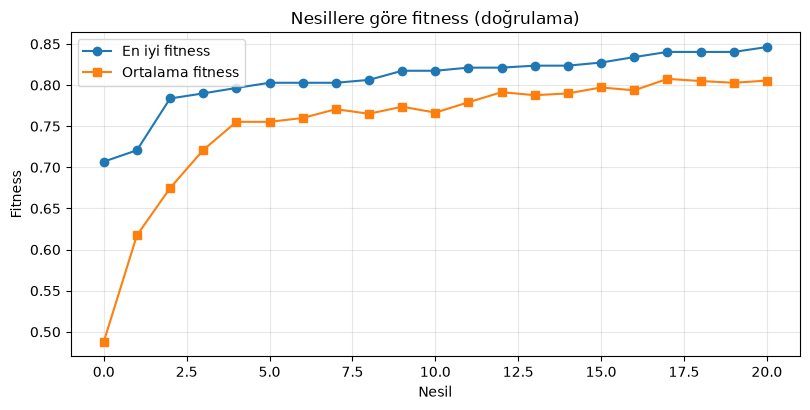

In [7]:
NESIL_SAYISI = 20  # en az 10

def pop_tablosu(pop):
    kayit = []
    for i, krom in enumerate(pop):
        fitness, basari, n = uygunluk(krom)
        kayit.append({
            'birey': i,
            'piksel': n,
            'dogrulama_basarisi': round(basari, 4),
            'fitness': round(fitness, 4),
            'kromozom': bit_yazi(krom),
        })
    return pd.DataFrame(kayit)

def ozet(ad, tablo):
    print(
        f"{ad} | en iyi fitness={tablo['fitness'].max():.4f} | "
        f"ortalama fitness={tablo['fitness'].mean():.4f} | "
        f"en iyi piksel={int(tablo.loc[tablo['fitness'].idxmax(), 'piksel'])}"
    )

def yeni_nesil(pop, skorlar):
    sira = sorted(range(len(pop)), key=lambda i: skorlar[i], reverse=True)
    yeni = [pop[i].copy() for i in sira[:ELIT_SAYISI]]
    while len(yeni) < len(pop):
        e1 = turnuva_sec(pop, skorlar)
        e2 = turnuva_sec(pop, skorlar)
        c1, c2, _ = caprazla(e1, e2)
        m1, _ = mutasyon(c1)
        yeni.append(m1)
        if len(yeni) < len(pop):
            m2, _ = mutasyon(c2)
            yeni.append(m2)
    return yeni

print('Ayarlar: popülasyon', POP_BOYUTU, '| nesil', NESIL_SAYISI,
      '| elit', ELIT_SAYISI, '| turnuva', TURNUVA_K,
      '| çapraz olasılığı', CAPRAZ_OLASILIK, '| bit mutasyon olasılığı', MUTASYON_P)
print()

pop = [k.copy() for k in populasyon]
eski = pop_tablosu(pop)
print('ESKİ POPÜLASYON (nesil 0)')
print(eski.drop(columns='kromozom').to_string(index=False))
print()
print('Eski kromozomlar:')
print(eski[['birey', 'piksel', 'kromozom']].to_string(index=False))
ozet('Eski özet', eski)
print()

tarih_en_iyi = [float(eski['fitness'].max())]
tarih_ortalama = [float(eski['fitness'].mean())]
tarih_piksel = [int(eski.loc[eski['fitness'].idxmax(), 'piksel'])]
tarih_basari = [float(eski.loc[eski['fitness'].idxmax(), 'dogrulama_basarisi'])]

for nesil in range(1, NESIL_SAYISI + 1):
    skorlar = [uygunluk(k)[0] for k in pop]
    pop = yeni_nesil(pop, skorlar)
    anlik = pop_tablosu(pop)
    en_iyi = float(anlik['fitness'].max())
    ortalama = float(anlik['fitness'].mean())
    piksel = int(anlik.loc[anlik['fitness'].idxmax(), 'piksel'])
    basari = float(anlik.loc[anlik['fitness'].idxmax(), 'dogrulama_basarisi'])
    tarih_en_iyi.append(en_iyi)
    tarih_ortalama.append(ortalama)
    tarih_piksel.append(piksel)
    tarih_basari.append(basari)
    print(
        f'Nesil {nesil:02d} | en iyi fitness={en_iyi:.4f} | ortalama={ortalama:.4f} | '
        f'en iyi piksel={piksel:2d} | doğrulama={basari:.4f}'
    )

yeni = pop_tablosu(pop)
print()
print(f'YENİ POPÜLASYON (nesil {NESIL_SAYISI})')
print(yeni.drop(columns='kromozom').to_string(index=False))
print()
print('Yeni kromozomlar:')
print(yeni[['birey', 'piksel', 'kromozom']].to_string(index=False))
ozet('Yeni özet', yeni)

en_iyi_satir = int(yeni['fitness'].idxmax())
en_iyi_kromozom = pop[en_iyi_satir].copy()
print()
print('Seçilen son kromozom (8×8 maske, 1 = açık piksel):')
print(en_iyi_kromozom.reshape(8, 8))
print('Bit dizisi:', bit_yazi(en_iyi_kromozom))
print(
    f"Piksel: {piksel_sayisi(en_iyi_kromozom)} / 64 | "
    f"doğrulama başarısı: {yeni.loc[en_iyi_satir, 'dogrulama_basarisi']:.4f} | "
    f"fitness: {yeni.loc[en_iyi_satir, 'fitness']:.4f}"
)

fig, ax = plt.subplots(figsize=(8.2, 4.2))
nesiller = range(0, NESIL_SAYISI + 1)
ax.plot(nesiller, tarih_en_iyi, marker='o', label='En iyi fitness')
ax.plot(nesiller, tarih_ortalama, marker='s', label='Ortalama fitness')
ax.set_xlabel('Nesil')
ax.set_ylabel('Fitness')
ax.set_title('Nesillere göre fitness (doğrulama)')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


## Görev 7 — Sonuçların karşılaştırılması

Aynı eğitilmiş YSA ile test verisinde iki durumu karşılaştırın: **64 pikselin tamamı** ve **GA'nın seçtiği pikseller**.

**Çıktı:** İki test doğruluğu, seçilen piksel sayısı, 8×8 maske görüntüsü ve örnek orijinal/maskeli rakam görüntüsü. Doğruluk farkını ve piksel azalmasını yorumlayın.


Tüm pikseller (64) test başarısı : 0.9528  (95.28%)
GA maskesi (37 piksel) test başarısı : 0.9167  (91.67%)
Doğruluk farkı (tam − GA)        : 0.0361  (3.61 puan)
Seçilen piksel                    : 37 / 64
Kapatılan piksel                  : 27  (42.2% azalma)

Yorum
- GA 37 pikseli açık bıraktı, 27 pikseli kapattı (42.2% azalma).
- Aynı ağırlıklarla test başarısı 95.28% iken 91.67% oldu.
- Fark 3.61 puan.
- Ağ bu maskeyle yeniden eğitilmedi. Kapalı piksel, test anında 0 olarak girer.
- Fitness, doğruluğu koruyan daha kısa maskeyi öne çıkardı.
- Rakam görüntülerinde kenar pikseller çoğu zaman boştur; onları kapatmak şekli silmez.
- 12–20 piksele inmek ortadaki ayırt edici pikselleri de götürdüğü için başarı düşer.
- 20 nesil bu dengeyi aradı: az piksel, doğrulama başarısına yakın bir test sonucu.


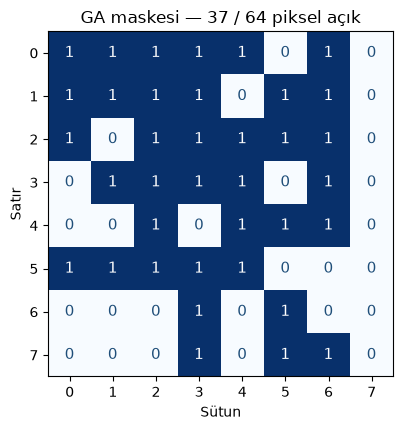

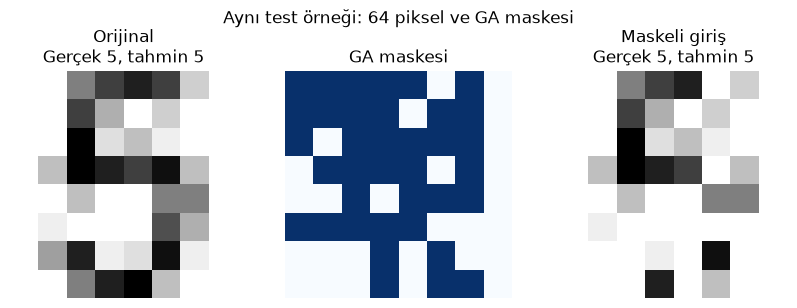

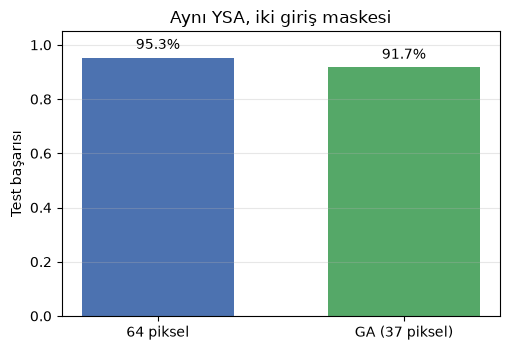

In [8]:
# Test kümesi ilk kez burada kullanılıyor.
tam_kromozom = np.ones(N_PIKSEL, dtype=np.int8)
acc_tam = basari_olc(tam_kromozom, X_test, y_test)
acc_ga = basari_olc(en_iyi_kromozom, X_test, y_test)
n_ga = piksel_sayisi(en_iyi_kromozom)
fark = acc_tam - acc_ga
azalma = N_PIKSEL - n_ga

print(f'Tüm pikseller (64) test başarısı : {acc_tam:.4f}  ({acc_tam * 100:.2f}%)')
print(f'GA maskesi ({n_ga} piksel) test başarısı : {acc_ga:.4f}  ({acc_ga * 100:.2f}%)')
print(f'Doğruluk farkı (tam − GA)        : {fark:.4f}  ({fark * 100:.2f} puan)')
print(f'Seçilen piksel                    : {n_ga} / 64')
print(f'Kapatılan piksel                  : {azalma}  ({azalma / N_PIKSEL * 100:.1f}% azalma)')
print()
print('Yorum')
print(f'- GA {n_ga} pikseli açık bıraktı, {azalma} pikseli kapattı ({azalma / N_PIKSEL * 100:.1f}% azalma).')
print(f'- Aynı ağırlıklarla test başarısı {acc_tam * 100:.2f}% iken {acc_ga * 100:.2f}% oldu.')
print(f'- Fark {fark * 100:.2f} puan.')
print('- Ağ bu maskeyle yeniden eğitilmedi. Kapalı piksel, test anında 0 olarak girer.')
print('- Fitness, doğruluğu koruyan daha kısa maskeyi öne çıkardı.')
print('- Rakam görüntülerinde kenar pikseller çoğu zaman boştur; onları kapatmak şekli silmez.')
print('- 12–20 piksele inmek ortadaki ayırt edici pikselleri de götürdüğü için başarı düşer.')
print('- 20 nesil bu dengeyi aradı: az piksel, doğrulama başarısına yakın bir test sonucu.')

fig, ax = plt.subplots(figsize=(4.4, 4.4))
maske = en_iyi_kromozom.reshape(8, 8)
ax.imshow(maske, cmap='Blues', vmin=0, vmax=1)
for satir in range(8):
    for sutun in range(8):
        deger = int(maske[satir, sutun])
        ax.text(
            sutun, satir, str(deger),
            ha='center', va='center',
            color='white' if deger else '#1f4e79',
            fontsize=11,
        )
ax.set_title(f'GA maskesi — {n_ga} / 64 piksel açık')
ax.set_xlabel('Sütun')
ax.set_ylabel('Satır')
ax.set_xticks(range(8))
ax.set_yticks(range(8))
fig.tight_layout()
plt.show()

ornek_idx = int(np.where(y_test == 5)[0][0])
ham = X_test[ornek_idx]
maskeli = ham * en_iyi_kromozom.astype(np.float32)
tahmin_tam = int(np.argmax(model(ham.reshape(1, -1), training=False).numpy(), axis=1)[0])
tahmin_ga = int(np.argmax(model(maskeli.reshape(1, -1), training=False).numpy(), axis=1)[0])
gercek = int(y_test[ornek_idx])

fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.1))
axes[0].imshow(ham.reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
axes[0].set_title(f'Orijinal\nGerçek {gercek}, tahmin {tahmin_tam}')
axes[1].imshow(maske, cmap='Blues', vmin=0, vmax=1)
axes[1].set_title('GA maskesi')
axes[2].imshow(maskeli.reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
axes[2].set_title(f'Maskeli giriş\nGerçek {gercek}, tahmin {tahmin_ga}')
for ax in axes:
    ax.axis('off')
fig.suptitle('Aynı test örneği: 64 piksel ve GA maskesi')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 3.6))
cubuklar = ax.bar(
    ['64 piksel', f'GA ({n_ga} piksel)'],
    [acc_tam, acc_ga],
    color=['#4C72B0', '#55A868'],
    width=0.62,
)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Test başarısı')
ax.set_title('Aynı YSA, iki giriş maskesi')
for cubuk, deger in zip(cubuklar, (acc_tam, acc_ga)):
    ax.text(
        cubuk.get_x() + cubuk.get_width() / 2,
        deger + 0.02,
        f'{deger * 100:.1f}%',
        ha='center', va='bottom',
    )
ax.grid(True, axis='y', alpha=0.3)
fig.tight_layout()
plt.show()


## Sonuç ve teslim

GA, eğitilmiş sinir ağının ağırlıklarını sabit tutup hangi piksellerin açık kalacağını aradı. İstediğim şey, doğrulama başarısını yüksek tutarken piksel sayısını 12 ile 48 arasına indirmekti.

Fitness şöyle: doğrulama başarısı − 0.20 × (piksel sayısı / 64). Aralık dışındaki kromozom −1 aldı, yani seçilemedi. Ebeveyn 3 kişilik turnuvayla seçildi, çaprazlama tek noktadan yapıldı, mutasyon biti tersine çevirdi. Her nesilde en iyi 2 birey elit olarak yeni popülasyona aynen geçti. Popülasyon 24 birey, evrim 20 nesil.

Başlangıçta en iyi fitness **0.7069** idi: 46 piksel, doğrulama başarısı **%85.07**. Ortalama fitness **0.4880**. 20. nesilde en iyi fitness **0.8462** oldu: **37 piksel**, doğrulama başarısı **%96.18**. Ortalama fitness **0.8055**'e çıktı. 64 pikselin tamamıyla alınan doğrulama başarısı **%96.53** olduğu için GA, doğrulamada neredeyse aynı başarıya 27 piksel eksikle ulaştı.

Test kümesini yalnız bu son karşılaştırmada kullandım. 64 pikselde test başarısı **%95.28**, GA maskesinde **%91.67**. Fark **3.61 puan**. Kapatılan piksel 27; bu, girdinin **%42.2**'si.

Buna göre 64 pikselin tamamı şart değil. Kenar pikseller çoğu rakamda zaten boş; GA onları kapatınca rakamın şekli duruyor. Testteki 3.61 puanlık fark, ağın bu maskeyle hiç eğitilmemesinden ve fitness fonksiyonunun test kümesini görmemesinden geliyor. Piksel sayısını 12–20 bandına zorlamak ise ortadaki ayırt edici pikselleri de sildiği için doğrulamada başarıyı düşürüyor. 0.20 ceza katsayısı bu ikisinin ortasında, 37 pikselde kaldı.

Teslim dosyası bu not defteridir: kod, çıktı ve grafikler birlikte kayıtlı. Colab'da **Runtime → Run all** aynı `SEED = 42` sırasını baştan üretir.
